# Conditional Flow Matching with Classifier Free Guidance

In [1]:
import time

import torch 
from torch import nn, Tensor
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import numpy as np

import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')

### Load MNIST dataset

In [ ]:


# Normalize pixel values from [0, 1] to [-1, 1] so the data matches a standard
# Gaussian source for flow matching.
transform = transforms.Compose([
    transforms.ToTensor(),
])

train_dataset = datasets.MNIST(root='../../data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='../../data', train=False, download=True, transform=transform)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f'Train samples: {len(train_dataset)}, Test samples: {len(test_dataset)}')
images, labels = next(iter(train_loader))
print(f'Batch images shape: {images.shape}, labels shape: {labels.shape}')

100.0%
100.0%
100.0%
100.0%

Train samples: 60000, Test samples: 10000
Batch images shape: torch.Size([128, 1, 28, 28]), labels shape: torch.Size([128])


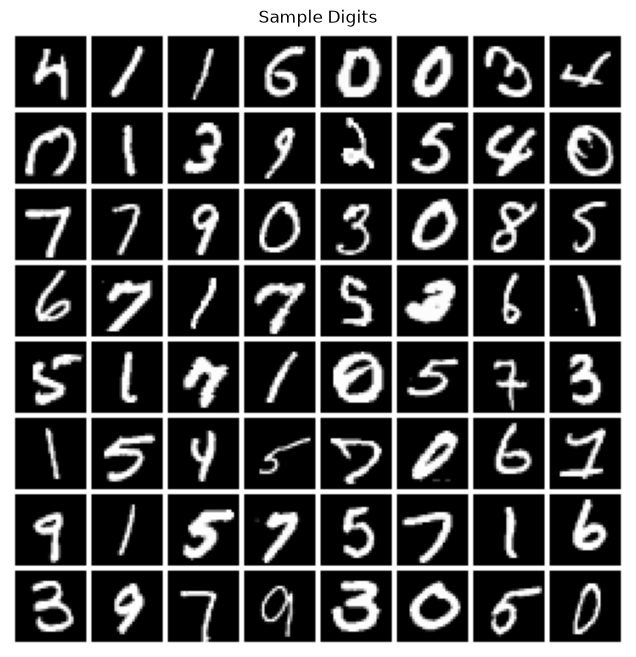

In [4]:
## Display some sample digits

def show_samples(images: Tensor, nrow: int=8, ax=None):
    # images = (images + 1) / 2  # denormalize
    images = images.clamp(0, 1)
    grid = make_grid(images[:nrow**2], nrow, padding=2, pad_value=1)
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 8))
    ax.set_aspect('equal')
    ax.set_title('Sample Digits')
    ax.imshow(grid.permute(1, 2, 0).cpu())
    ax.axis('off')
    return ax

show_samples(images);

## Classifier-Free Guidance

The velocity field is conditioned on the class label $c$ via a learned embedding. During training, labels are randomly replaced with a null token (`c=10`) with probability $\eta$, so the network also learns an unconditional field. At inference, the guided field is a mixture:

$$v_w(x_t, t, c) = w \cdot v_\theta(x_t, t, c) + (1-w) \cdot v_\theta(x_t, t, \varnothing)$$

Higher $w$ sharpens the class conditioning at the cost of diversity.

In [10]:
class CondFlow(nn.Module):
    def __init__(self, dim: int = 784, h: int = 64):
        super().__init__()
        self.class_emb = nn.Embedding(10 + 1, dim)
        self.encoder = nn.Sequential(
            nn.Linear(dim+1, h),
            nn.ReLU(),
            nn.Linear(h, h),
        )
        self.decoder = nn.Sequential(
            nn.Linear(h, h),
            nn.ReLU(),
            nn.Linear(h, dim),
            # nn.Sigmoid()
        )
    
    def forward(self, t: Tensor, c: Tensor, x_t: Tensor ) -> Tensor:
        c_emb = self.class_emb(c)
        inp = torch.cat((x_t + c_emb, t), 1)
        z = self.encoder(inp)
        return self.decoder(z)

    def cfg_forward(self, t: Tensor, c: Tensor, x_t: Tensor, w: float) -> Tensor:
        return self.forward(t, c, x_t) * w + self.forward(t, torch.full_like(c, 10), x_t) * (1 - w)

    def step(self, x_t: Tensor, t_start: Tensor, t_end: Tensor, c: Tensor, w: float) -> Tensor:
        t_start = t_start.view(1, 1).expand(x_t.shape[0], 1)
        dt = t_end - t_start
        return x_t + dt * self.cfg_forward(x_t=x_t + self.cfg_forward(x_t=x_t, t=t_start, c=c, w=w)*dt/2, t=t_start + dt/2, c=c, w=w)

In [ ]:
N_EPOCHS = 30
SIGMA_NOISE = 0.1
ETA = 0.1

cond_flow = CondFlow(h=512).to(device)
opt = torch.optim.Adam(cond_flow.parameters(), lr=1e-3)
losses = []
preds = []
for e in range(N_EPOCHS):
    tot_loss = 0
    n = 0
    for i, (x, l) in enumerate(train_loader):
        x_1 = x.view(-1, 784).to(device)
        l = l.to(device)

        # Randomly replace labels with the null token to enable classifier-free guidance
        l[torch.rand(l.shape[0], device=l.device) < ETA] = 10

        t = torch.rand(x.shape[0], 1, device=x_1.device)
        x_0 = torch.randn_like(x_1)*SIGMA_NOISE + 0.5
        dx_t = x_1 - x_0
        x_t = (1-t)*x_0 + t * x_1
        flow_pred = cond_flow(x_t=x_t, t=t, c=l)

        loss = (flow_pred - dx_t).pow(2).sum(dim=1).mean()
        loss.backward()
        tot_loss += loss.item()
        n += 1
        opt.step()
        opt.zero_grad()

    preds.append(flow_pred[0].cpu().detach().numpy())
    losses.append(tot_loss/n)
    print(f'\r[{100*(e+1)/N_EPOCHS:.0f}%] Epoch {e+1}/{N_EPOCHS}  loss: {tot_loss/n:.4f}', end='', flush=True)

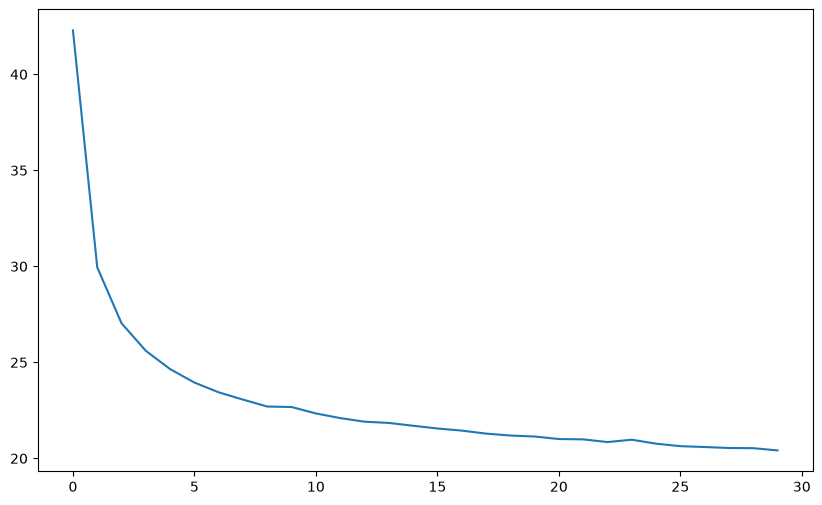

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(losses)
plt.show();

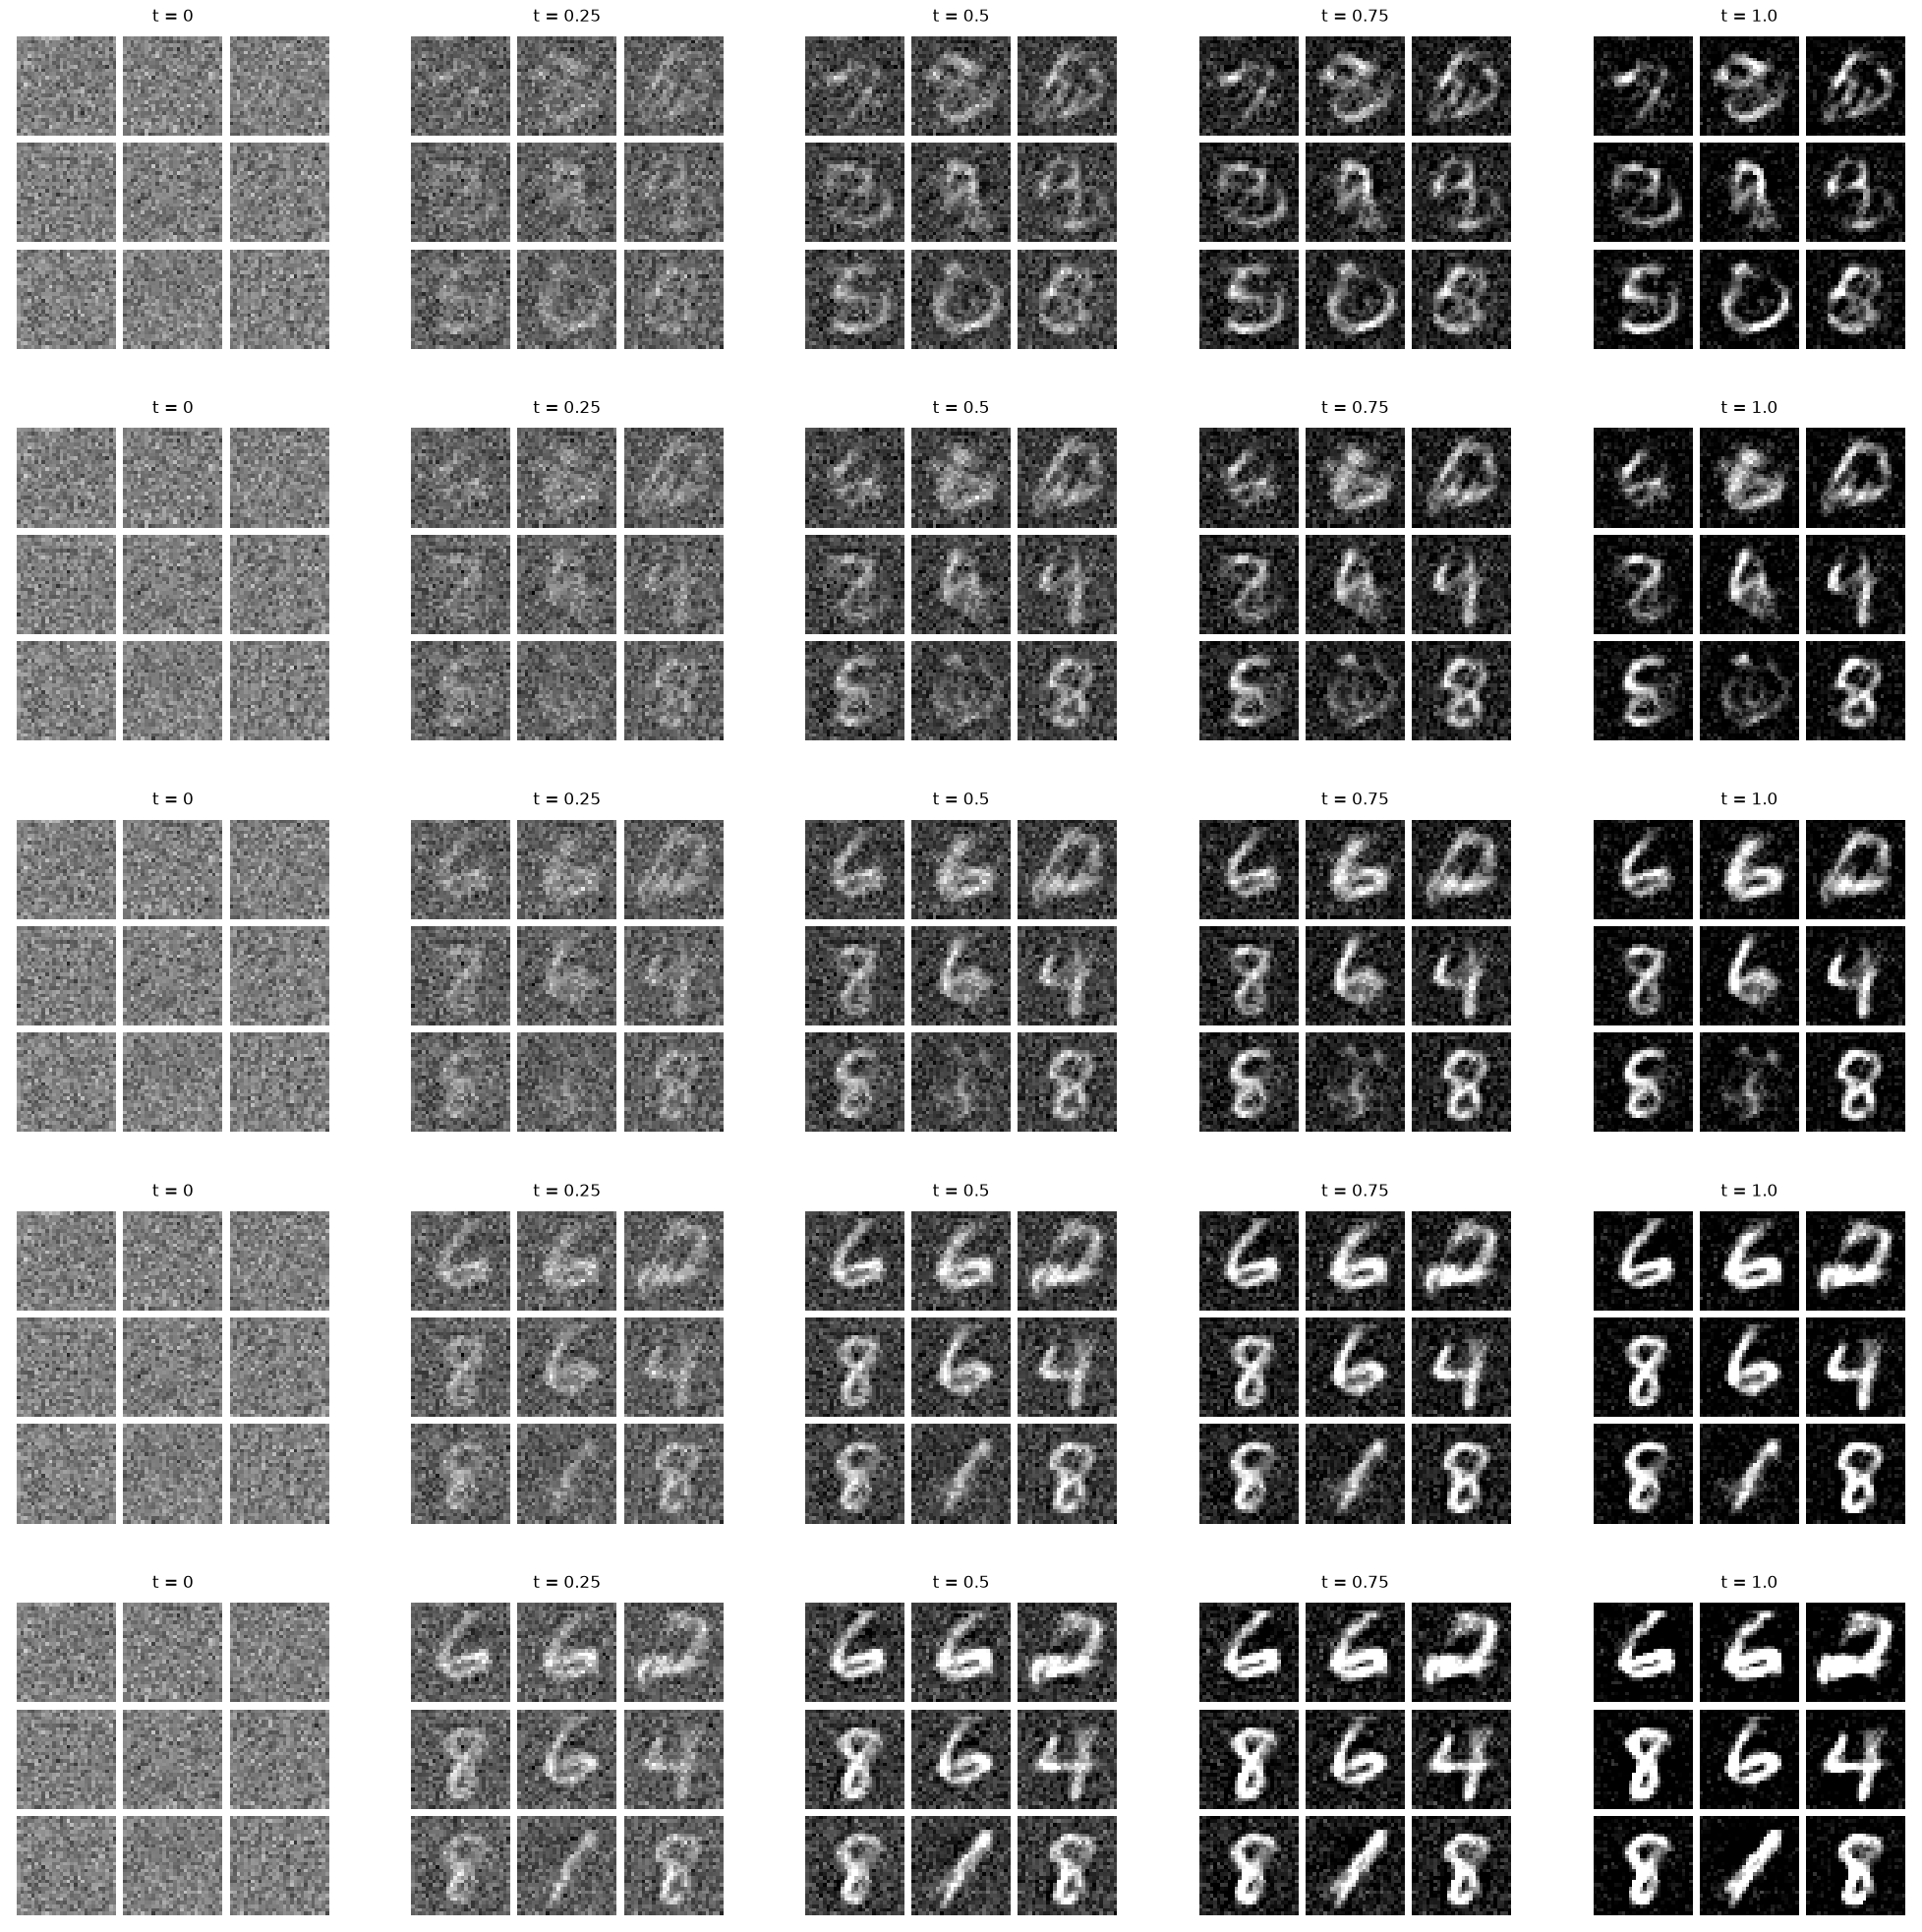

In [22]:
ws = [0, 0.5, 1, 2, 4]  # Guidance scale

x_init = torch.randn(9, 784).to(device)
l = torch.randint(10, (9,)).to(device)


n_steps = 100
time_steps = torch.linspace(0, 1.0, n_steps + 1)
states = {}


# Precompute the point cloud at every time step.
for w in ws:
    x = x_init * SIGMA_NOISE + 0.5
    states[w] = [x]
    with torch.no_grad():
        for i in range(n_steps):
            x = cond_flow.step(x_t=x, t_start=time_steps[i].to(device), t_end=time_steps[i + 1].to(device), c=l, w=w)
            states[w].append(x)
    states[w] = [s.detach() for s in states[w]]

fig, ax = plt.subplots(len(ws), 5, figsize=(25, 5*len(ws)))
for i, w in enumerate(ws):
    ax[i, 0] = show_samples(states[w][0].view(-1, 1, 28, 28), nrow=3, ax=ax[i, 0])
    ax[i, 0].set_title('t = 0')
    ax[i, 1] = show_samples(states[w][int(n_steps*0.25)].view(-1, 1, 28, 28), nrow=3, ax=ax[i, 1])
    ax[i, 1].set_title('t = 0.25')
    ax[i, 2] = show_samples(states[w][int(n_steps*0.5)].view(-1, 1, 28, 28), nrow=3, ax=ax[i, 2])
    ax[i, 2].set_title('t = 0.5')
    ax[i, 3] = show_samples(states[w][int(n_steps*0.75)].view(-1, 1, 28, 28), nrow=3, ax=ax[i, 3])
    ax[i, 3].set_title('t = 0.75')
    ax[i, 4] = show_samples(states[w][-1].view(-1, 1, 28, 28), nrow=3, ax=ax[i, 4])
    ax[i, 4].set_title('t = 1.0')

plt.show();

In [25]:
ws = [0, 0.5, 1, 2, 4]  # Guidance scale

x_init = torch.randn(25, 784).to(device)
l = torch.Tensor(np.arange(25) % 10).long().to(device)


n_steps = 100
time_steps = torch.linspace(0, 1.0, n_steps + 1)

gen_samples = {}
for w in ws:
    x = x_init * SIGMA_NOISE + 0.5
    with torch.no_grad():
        for i in range(n_steps):
            x = cond_flow.step(x_t=x, t_start=time_steps[i].to(device), t_end=time_steps[i + 1].to(device), c=l, w=w)
    gen_samples[w] = x.detach()

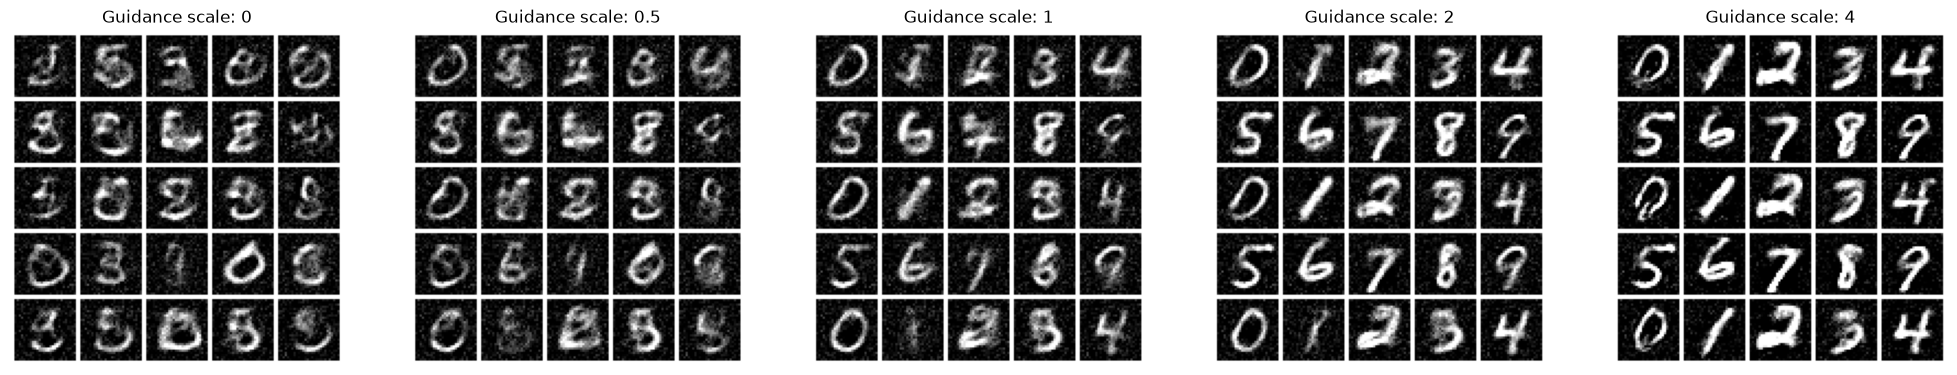

In [26]:
fig, ax = plt.subplots(1, len(ws), figsize=(5*len(ws), 6))
for i, w in enumerate(ws):
    ax[i] = show_samples(gen_samples[w].view(-1, 1, 28, 28), nrow=5, ax=ax[i])
    ax[i].set_title(f'Guidance scale: {w}')
plt.show();